# PyTorch PINN for the 1-D heat equation

This notebook predicts how a bar cools over a normalized time interval $0\leq t\leq1$. It compares two small **tanh** networks with identical starting weights:

1. A supervised network fits sparse, noisy temperature measurements plus known initial and boundary values.
2. A physics-informed neural network (PINN) uses those same values and also penalizes the heat-equation residual throughout the space-time domain.

Both networks take **position and time** $(x,t)$ as input and predict temperature $u(x,t)$. The interior measurements cover only $0\leq t\leq0.35$, while predictions are checked through $t=1$. This makes the later part of the time window a meaningful test. Run the cells from top to bottom.

## 1. Heat-transfer problem

For a one-dimensional bar with normalized length and constant thermal diffusivity $\alpha=0.15$,

$$u_t=\alpha u_{xx},\qquad 0<x<1,\quad 0<t\leq1.$$

The ends stay at zero temperature: $u(0,t)=u(1,t)=0$. Initially, $u(x,0)=\sin(\pi x)$. This simple case has an exact solution:

$$u(x,t)=e^{-\alpha\pi^2 t}\sin(\pi x).$$

We use that solution to generate noisy interior readings and to evaluate the learned responses. Neither network trains on the clean interior field. The units are normalized so the focus stays on the PINN setup.

Matplotlib is building the font cache; this may take a moment.


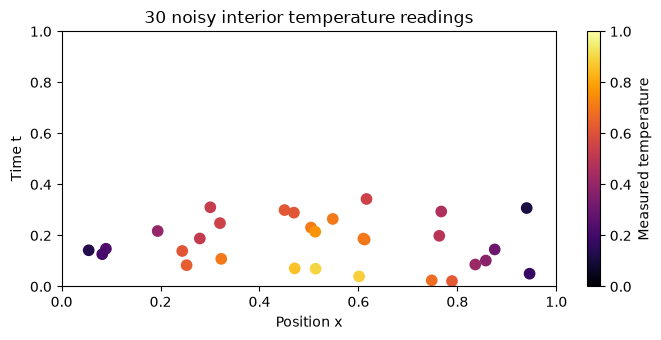

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(10)
rng = np.random.default_rng(7)
alpha = 0.15

def exact_temperature(x, t):
    return np.exp(-alpha * np.pi**2 * t) * np.sin(np.pi * x)

# Interior sensors measure only the early part of the response.
n_obs = 30
x_obs = rng.uniform(0.05, 0.95, n_obs)
t_obs = rng.uniform(0.02, 0.35, n_obs)
u_obs = exact_temperature(x_obs, t_obs) + rng.normal(0, 0.03, n_obs)
xt_obs = torch.tensor(np.column_stack((x_obs, t_obs)), dtype=torch.float32)
u_obs_tensor = torch.tensor(u_obs[:, None], dtype=torch.float32)

# Known initial temperature and zero-temperature ends.
x_initial = np.linspace(0, 1, 41)
xt_initial = torch.tensor(np.column_stack((x_initial, np.zeros(41))), dtype=torch.float32)
u_initial = torch.tensor(np.sin(np.pi * x_initial)[:, None], dtype=torch.float32)
t_boundary = np.linspace(0, 1, 41)
xt_left = torch.tensor(np.column_stack((np.zeros(41), t_boundary)), dtype=torch.float32)
xt_right = torch.tensor(np.column_stack((np.ones(41), t_boundary)), dtype=torch.float32)

fig, ax = plt.subplots(figsize=(7, 3.5))
scatter = ax.scatter(x_obs, t_obs, c=u_obs, cmap='inferno', vmin=0, vmax=1, s=55)
ax.set(xlabel='Position x', ylabel='Time t', title='30 noisy interior temperature readings', xlim=(0, 1), ylim=(0, 1))
fig.colorbar(scatter, ax=ax, label='Measured temperature')
fig.tight_layout()
plt.show()


## 2. Supervised reference network

The loss combines the 30 noisy interior readings with the known initial profile and end temperatures. It has no PDE term. We use all points in each update to keep the small example easy to follow.

In [2]:
torch.manual_seed(10)
data_net = nn.Sequential(
    nn.Linear(2, 32), nn.Tanh(),
    nn.Linear(32, 32), nn.Tanh(),
    nn.Linear(32, 32), nn.Tanh(),
    nn.Linear(32, 1)
)
data_optimizer = torch.optim.Adam(data_net.parameters(), lr=0.001)
epochs = 4000
data_losses = []

for epoch in range(epochs):
    data_optimizer.zero_grad()
    observation_loss = torch.mean((data_net(xt_obs) - u_obs_tensor) ** 2)
    initial_loss = torch.mean((data_net(xt_initial) - u_initial) ** 2)
    boundary_loss = torch.mean(data_net(xt_left) ** 2) + torch.mean(data_net(xt_right) ** 2)
    loss = observation_loss + initial_loss + boundary_loss
    loss.backward()
    data_optimizer.step()
    data_losses.append(loss.item())


## 3. Physics-informed network

The PINN has the **same architecture, initialization, observations, initial values, and boundary values**. It also checks the residual

$$r(x,t)=u_{t,\mathrm{net}}(x,t)-\alpha u_{xx,\mathrm{net}}(x,t)$$

at 256 interior space-time points. PyTorch automatic differentiation computes $u_t$ and $u_{xx}$. The physics loss is the mean of $r^2$. We give all four losses equal weight for this classroom example.

In [3]:
torch.manual_seed(10)
pinn = nn.Sequential(
    nn.Linear(2, 32), nn.Tanh(),
    nn.Linear(32, 32), nn.Tanh(),
    nn.Linear(32, 32), nn.Tanh(),
    nn.Linear(32, 1)
)
pinn_optimizer = torch.optim.Adam(pinn.parameters(), lr=0.001)
pinn_losses = []

# Fixed collocation points cover the full prediction window, including later times.
xt_physics = torch.rand(256, 2).requires_grad_(True)

for epoch in range(epochs):
    pinn_optimizer.zero_grad()
    observation_loss = torch.mean((pinn(xt_obs) - u_obs_tensor) ** 2)
    initial_loss = torch.mean((pinn(xt_initial) - u_initial) ** 2)
    boundary_loss = torch.mean(pinn(xt_left) ** 2) + torch.mean(pinn(xt_right) ** 2)

    # Differentiate network output with respect to position x and time t.
    u_physics = pinn(xt_physics)
    derivatives = torch.autograd.grad(
        u_physics, xt_physics, torch.ones_like(u_physics), create_graph=True
    )[0]
    u_x = derivatives[:, 0:1]
    u_t = derivatives[:, 1:2]
    u_xx = torch.autograd.grad(
        u_x, xt_physics, torch.ones_like(u_x), create_graph=True
    )[0][:, 0:1]
    physics_loss = torch.mean((u_t - alpha * u_xx) ** 2)

    loss = observation_loss + initial_loss + boundary_loss + physics_loss
    loss.backward()
    pinn_optimizer.step()
    pinn_losses.append(loss.item())


## 4. Temperature field across space and time

The first figure compares the exact field with both predictions. The second uses the **same color scale** for both absolute-error maps. The dashed line marks the latest interior observation time, $t=0.35$. Temperatures above that line are later-time predictions.

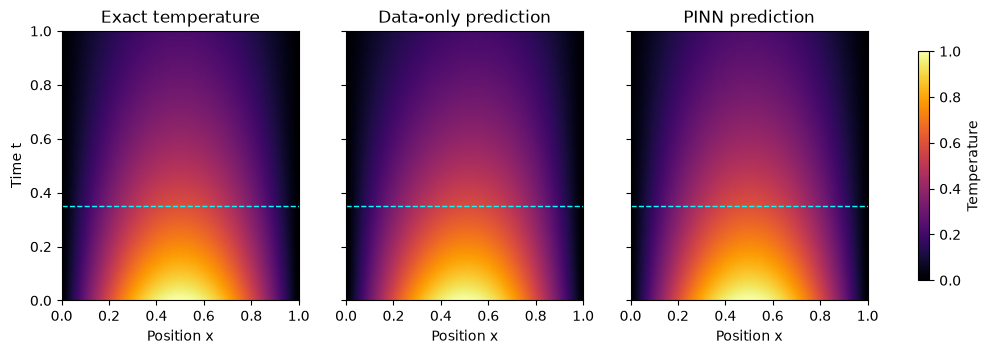

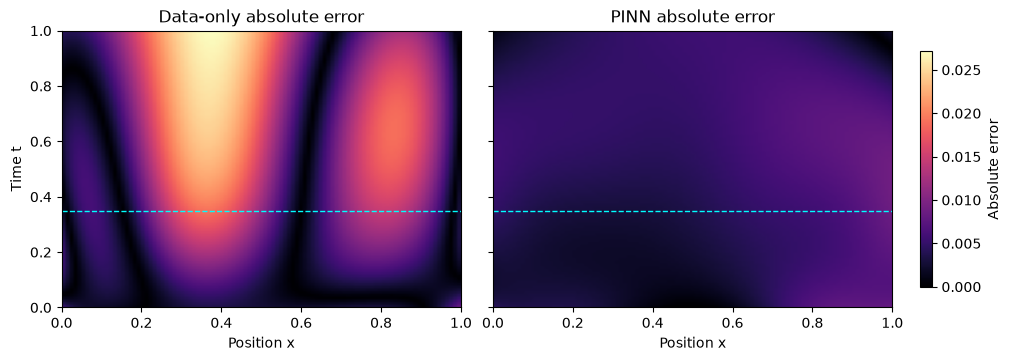

Data only RMSE: early 0.0070, later 0.0146
PINN      RMSE: early 0.0042, later 0.0054


In [4]:
x_grid = np.linspace(0, 1, 101)
t_grid = np.linspace(0, 1, 101)
X, T = np.meshgrid(x_grid, t_grid)
xt_grid = torch.tensor(np.column_stack((X.ravel(), T.ravel())), dtype=torch.float32)
u_exact = exact_temperature(X, T)

with torch.no_grad():
    u_data = data_net(xt_grid).numpy().reshape(X.shape)
    u_pinn = pinn(xt_grid).numpy().reshape(X.shape)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharex=True, sharey=True)
for ax, field, title in zip(
    axes, [u_exact, u_data, u_pinn],
    ['Exact temperature', 'Data-only prediction', 'PINN prediction']
):
    image = ax.imshow(field, origin='lower', extent=(0, 1, 0, 1), aspect='auto', cmap='inferno', vmin=0, vmax=1)
    ax.axhline(0.35, color='cyan', linestyle='--', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel('Position x')
axes[0].set_ylabel('Time t')
fig.colorbar(image, ax=axes, label='Temperature', shrink=0.85)
plt.show()

data_error = np.abs(u_data - u_exact)
pinn_error = np.abs(u_pinn - u_exact)
error_limit = max(data_error.max(), pinn_error.max())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True, sharey=True, constrained_layout=True)
for ax, error, title in zip(
    axes, [data_error, pinn_error],
    ['Data-only absolute error', 'PINN absolute error']
):
    image = ax.imshow(error, origin='lower', extent=(0, 1, 0, 1), aspect='auto', cmap='magma', vmin=0, vmax=error_limit)
    ax.axhline(0.35, color='cyan', linestyle='--', linewidth=1)
    ax.set(title=title, xlabel='Position x')
axes[0].set_ylabel('Time t')
fig.colorbar(image, ax=axes, label='Absolute error', shrink=0.85, pad=0.02)
plt.show()

early = T <= 0.35
late = T > 0.35
for name, prediction in [('Data only', u_data), ('PINN', u_pinn)]:
    early_rmse = np.sqrt(np.mean((prediction[early] - u_exact[early]) ** 2))
    late_rmse = np.sqrt(np.mean((prediction[late] - u_exact[late]) ** 2))
    print(f'{name:9s} RMSE: early {early_rmse:.4f}, later {late_rmse:.4f}')


## 5. Temperature profiles and training loss

The profiles compare both networks with the exact solution at selected times. The loss curves show what each network minimized during training; the PINN loss includes an additional PDE term, so the final loss values are different kinds of quantities.

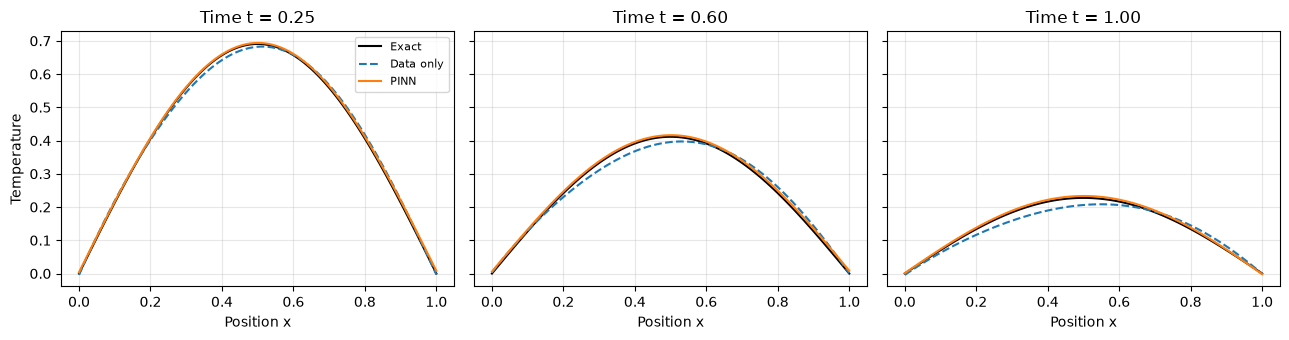

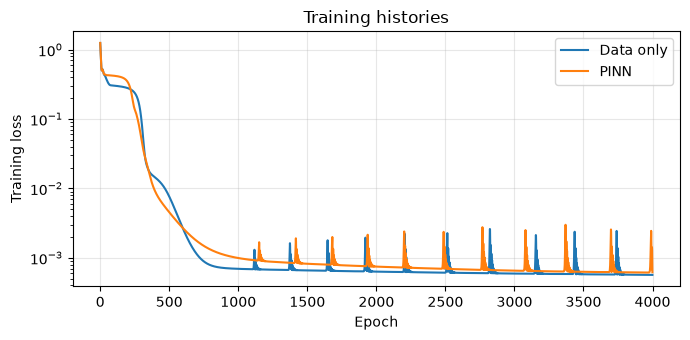

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, time in zip(axes, [0.25, 0.60, 1.0]):
    index = int(time * 100)
    ax.plot(x_grid, u_exact[index], 'k-', label='Exact')
    ax.plot(x_grid, u_data[index], color='tab:blue', linestyle='--', label='Data only')
    ax.plot(x_grid, u_pinn[index], color='tab:orange', label='PINN')
    ax.set(xlabel='Position x', title=f'Time t = {time:.2f}')
axes[0].set_ylabel('Temperature')
axes[0].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

plt.figure(figsize=(7, 3.5))
plt.semilogy(data_losses, label='Data only')
plt.semilogy(pinn_losses, label='PINN')
plt.xlabel('Epoch')
plt.ylabel('Training loss')
plt.title('Training histories')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Animated temperature bars

Each horizontal bar represents the same one-dimensional rod divided into 31 rectangular sections. The top bar shows the exact solution, the middle bar the data network, and the bottom bar the PINN. A fixed color scale maps dark colors to low temperature and bright colors to high temperature as time advances from $t=0$ to $t=1$. Interior measurements were available only through $t=0.35$. The GIF is saved beside this notebook and displayed below.

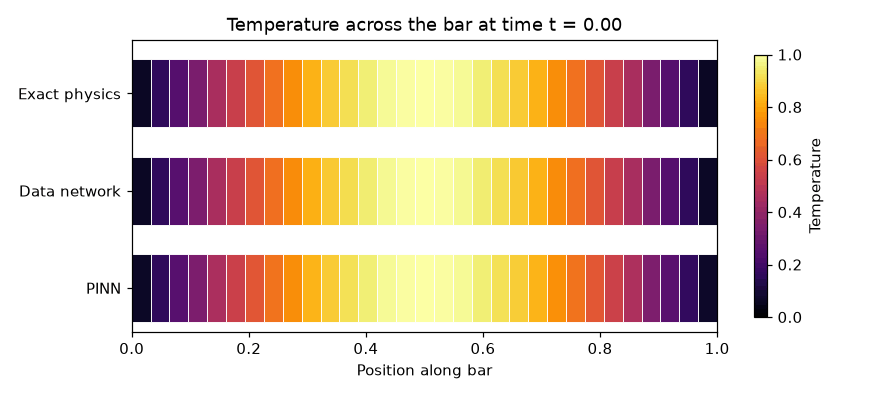

In [6]:
from pathlib import Path
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
from IPython.display import display, Image

segments = 31
segment_indices = np.rint((np.arange(segments) + 0.5) * 100 / segments).astype(int)
temperature_fields = [u_exact, u_data, u_pinn]
row_positions = [2.1, 1.1, 0.1]
color_scale = Normalize(vmin=0, vmax=1)
colors = plt.get_cmap('inferno')

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = []
for row_y, field in zip(row_positions, temperature_fields):
    row = []
    for section, grid_index in enumerate(segment_indices):
        rectangle = Rectangle(
            (section / segments, row_y), 1 / segments, 0.7,
            facecolor=colors(color_scale(field[0, grid_index])),
            edgecolor='white', linewidth=0.6
        )
        ax.add_patch(rectangle)
        row.append(rectangle)
    bars.append(row)

ax.set(xlim=(0, 1), ylim=(0, 3), xlabel='Position along bar',
       yticks=[2.45, 1.45, 0.45],
       yticklabels=['Exact physics', 'Data network', 'PINN'])
title = ax.set_title('Temperature across the bar at time t = 0.00')
fig.colorbar(plt.cm.ScalarMappable(norm=color_scale, cmap=colors),
             ax=ax, label='Temperature', shrink=0.9)
fig.tight_layout()

def update(frame):
    # Give each rectangular section the temperature at its position and time.
    for row, field in zip(bars, temperature_fields):
        for rectangle, grid_index in zip(row, segment_indices):
            rectangle.set_facecolor(colors(color_scale(field[frame, grid_index])))
    title.set_text(f'Temperature across the bar at time t = {t_grid[frame]:.2f}')

animation = FuncAnimation(fig, update, frames=range(0, 101, 2), interval=100)
gif_path = Path('heat_1d_temperature_animation.gif')
animation.save(gif_path, writer=PillowWriter(fps=10), dpi=110)
plt.close(fig)
display(Image(filename=str(gif_path)))


## 7. Animated prediction errors

These two segmented bars show each network's **absolute temperature error** relative to the exact physics solution. Every rectangle corresponds to the same position used in the temperature animation above. Both bars share one fixed color scale from zero to the largest error across the full time window, so the colors remain comparable as the animation plays. The GIF is saved beside this notebook and displayed below.

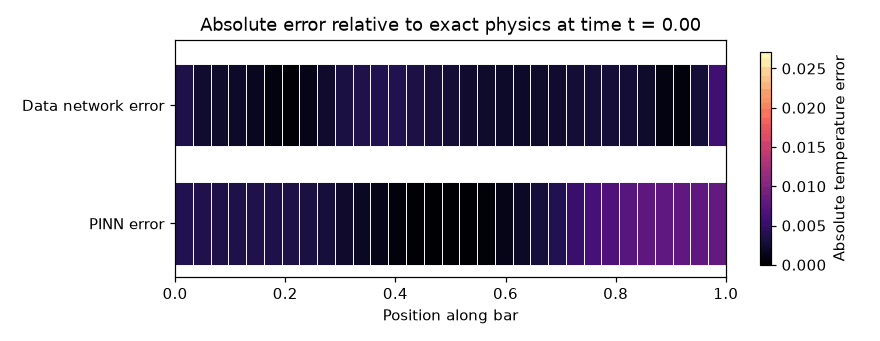

In [7]:
from pathlib import Path
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
from IPython.display import display, Image

data_error = np.abs(u_data - u_exact)
pinn_error = np.abs(u_pinn - u_exact)
error_fields = [data_error, pinn_error]
segments = 31
segment_indices = np.rint((np.arange(segments) + 0.5) * 100 / segments).astype(int)
error_scale = Normalize(vmin=0, vmax=max(data_error.max(), pinn_error.max()))
error_colors = plt.get_cmap('magma')

fig, ax = plt.subplots(figsize=(8, 3.1))
error_bars = []
for row_y, field in zip([1.1, 0.1], error_fields):
    row = []
    for section, grid_index in enumerate(segment_indices):
        rectangle = Rectangle(
            (section / segments, row_y), 1 / segments, 0.7,
            facecolor=error_colors(error_scale(field[0, grid_index])),
            edgecolor='white', linewidth=0.6
        )
        ax.add_patch(rectangle)
        row.append(rectangle)
    error_bars.append(row)

ax.set(xlim=(0, 1), ylim=(0, 2), xlabel='Position along bar',
       yticks=[1.45, 0.45],
       yticklabels=['Data network error', 'PINN error'])
error_title = ax.set_title('Absolute error relative to exact physics at time t = 0.00')
fig.colorbar(plt.cm.ScalarMappable(norm=error_scale, cmap=error_colors),
             ax=ax, label='Absolute temperature error', shrink=0.9)
fig.tight_layout()

def update_errors(frame):
    # Recolor both bars from their errors at the same time and position.
    for row, field in zip(error_bars, error_fields):
        for rectangle, grid_index in zip(row, segment_indices):
            rectangle.set_facecolor(error_colors(error_scale(field[frame, grid_index])))
    error_title.set_text(f'Absolute error relative to exact physics at time t = {t_grid[frame]:.2f}')

error_animation = FuncAnimation(fig, update_errors, frames=range(0, 101, 2), interval=100)
error_gif_path = Path('heat_1d_absolute_error_animation.gif')
error_animation.save(error_gif_path, writer=PillowWriter(fps=10), dpi=110)
plt.close(fig)
display(Image(filename=str(error_gif_path)))
